# VERIONCO — Notebook 05: Retrieval (Support & Counter)

**Purpose:** build three *separate*, independently-evaluable retrieval channels over
static evidence dumps on disk:

1. **Support retrieval** — evidence that positively supports a candidate
   hypothesis or treatment for a given patient.
2. **Counter retrieval** — evidence that contradicts, warns against, or reports
   resistance/failure/adverse evidence for the same hypothesis or treatment.
3. **Guideline retrieval** — passages from an attached clinical practice
   guideline corpus (ESMO, ASCO, NICE) that inform guideline-concordant
   management. Guideline hits are indexed into the same BM25 corpus as the
   other sources and tagged with `source="guideline"`.

Support and counter channels share a lexical index but use **different scoring
rules** so they are not trivially correlated. Guideline retrieval uses a
**dedicated BM25 pass** over the guideline subset to avoid length-normalization
bias (guideline chunks ≈ 2000 chars vs. PubMed titles ≈ 100 chars).

**Evidence sources indexed:**

| Source | Format | Approx. size | Role |
|--------|--------|--------------|------|
| PubMed MEDLINE | `pubmed.txt` | ~10k records | Literature support + counter |
| CIViC | `civic_evidence.tsv` | ~5k features | Variant/gene evidence |
| ClinicalTrials.gov | `clinicaltrials.json/*.json` | ~5.5k trials | Trial candidates |
| **Clinical practice guidelines** | `*.pdf` (ESMO / ASCO / NICE) | 3 documents → ~500–1000 chunks | Guideline-concordant management |

**Guideline corpus composition:**
- **ESMO 2025** — Early & Locally Advanced NSCLC (primary; ~95% of TCGA-LUAD is Stage I–III)
- **ASCO 2026** — Stage IV NSCLC With Driver Alterations (secondary)
- **NICE NG122** — Lung Cancer Diagnosis & Management (structural)

PDFs are parsed with `pypdf`, chunked into 2,000-character passages with
200-character overlap. Every chunk has a stable `source_id` of the form
`<pdf_stem>:<chunk_index>` (e.g., `esmo_mnsclc_2025:0042`).

**What this notebook is NOT:**
- It is not open-domain retrieval. It is retrieval against fixed on-disk snapshots.
- It does not fabricate citations. Every returned item has a `source_id` that
  must exist in the underlying dump (`_is_valid` hard check covers all four sources).
- It does not claim clinical truth. Hits are evidence candidates, not adjudicated evidence.
- It does not substitute for a licensed guideline product. NCCN is explicitly excluded.

**Leakage contract:** every artifact is keyed by `patient_id`. The guideline
corpus is patient-agnostic; only the query is patient-specific.

In [1]:
# ============================================================
# CONFIGURATION  ← edit only this cell
# ============================================================
from pathlib import Path
import os, gc, sys, json, hashlib, warnings, time, traceback, gc
from datetime import datetime, timezone
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

# Detect environment
IS_KAGGLE = Path("/kaggle").exists()

def find_dir(candidates, fallback):
    for c in candidates:
        p = Path(c)
        if p.exists():
            return p
    return Path(fallback)

OUTPUT_ROOT = Path("/kaggle/working/VERIONCO_outputs") if IS_KAGGLE else Path("./VERIONCO_outputs")
NB_OUTPUT       = OUTPUT_ROOT / "05"
NB_OUTPUT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_ROOT = OUTPUT_ROOT / "checkpoints" / "05"
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

PATHS = {
    "nb00": find_dir([
        "/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00",
        "/kaggle/input/verionco-outputs-00/00",
        "/kaggle/input/verionco-outputs-00",
        "/kaggle/input/verionco-outputs-local/00",
        "/kaggle/working/VERIONCO_outputs/00",
        "./VERIONCO_outputs/00"
    ], fallback="./VERIONCO_outputs/00" if not IS_KAGGLE else "/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00"),
    
    "nb02": find_dir([
        "/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02",
        "/kaggle/input/verionco-outputs-02",
        "/kaggle/input/verionco-outputs-local/02",
        "/kaggle/working/VERIONCO_outputs/02",
        "./VERIONCO_outputs/02"
    ], fallback="./VERIONCO_outputs/02" if not IS_KAGGLE else "/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02"),
    
    "nb03": find_dir([
        "/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03",
        "/kaggle/input/verionco-outputs-03",
        "/kaggle/input/verionco-outputs-local/03",
        "/kaggle/working/VERIONCO_outputs/03",
        "./VERIONCO_outputs/03"
    ], fallback="./VERIONCO_outputs/03" if not IS_KAGGLE else "/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03"),
    
    "nb04": find_dir([
        "/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04",
        "/kaggle/input/verionco-outputs-04",
        "/kaggle/input/verionco-outputs-local/04",
        "/kaggle/working/VERIONCO_outputs/04",
        "./VERIONCO_outputs/04"
    ], fallback="./VERIONCO_outputs/04" if not IS_KAGGLE else "/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04"),
    
    "retrieval": find_dir([
        "/kaggle/input/datasets/ayushsrivastava2000/raw-retrival",
        "/kaggle/input/raw-retrival",
        "/kaggle/input/datasets/ayushsrivastava2000/retrieval",
        "/kaggle/input/retrieval",
        "./data/retrieval"
    ], fallback="./data/retrieval" if not IS_KAGGLE else "/kaggle/input/datasets/ayushsrivastava2000/raw-retrival"),
    
    "guidelines": find_dir([
        "/kaggle/input/datasets/ayushsrivastava2000/verionco-guideline-corpus",
        "/kaggle/input/verionco-guideline-corpus",
        "./data/retrieval"
    ], fallback="./data/retrieval" if not IS_KAGGLE else "/kaggle/input/datasets/ayushsrivastava2000/verionco-guideline-corpus"),
}

EXPECTED_MIN_CASES = 10
EXPECTED_MAX_CASES = 550
PROJECT  = "VERIONCO"
NOTEBOOK = "05_retrieval_support_counter"

for k, v in PATHS.items():
    print(f"{k:12s} | {v} | exists={v.exists()}")

missing = [k for k, v in PATHS.items() if not v.exists()]
if missing:
    warnings.warn(f"Missing non-critical or optional roots: {missing}")

print(f"\nOutput:      {NB_OUTPUT}")
print(f"Checkpoints: {CHECKPOINT_ROOT}")


nb00       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00 | exists=True
nb02       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02 | exists=True
nb03       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03 | exists=True
nb04       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04 | exists=True
retrieval  | /kaggle/input/datasets/ayushsrivastava2000/raw-retrival | exists=True
guidelines | /kaggle/input/datasets/ayushsrivastava2000/verionco-guideline-corpus | exists=True

Output:      /kaggle/working/VERIONCO_outputs/05
Checkpoints: /kaggle/working/VERIONCO_outputs/checkpoints/05
Guideline chunk size: 2000 (overlap 200)
Guideline dedicated top-K: 3


In [2]:
import importlib.util
packages = ["pandas", "numpy", "scipy", "sklearn", "rank_bm25", "regex"]
rows = [{"package": p, "available": importlib.util.find_spec(p) is not None}
        for p in packages]
display(pd.DataFrame(rows))
print(json.dumps({
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
}, indent=2))

,package,available
0,pandas,True
1,numpy,True
2,scipy,True
3,sklearn,True
4,rank_bm25,False
5,regex,True


{
  "timestamp_utc": "2026-09-25T23:55:07.218397+00:00",
  "python": "3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]"
}


In [3]:
# ============================================================
# LOAD — cohort + upstream artifacts
# ============================================================
t0 = time.time()

def _safe_read_csv(p, **kw):
    p = Path(p)
    if not p.exists():
        print(f"  MISSING: {p}")
        return pd.DataFrame()
    return pd.read_csv(p, **kw)

def _safe_read_json(p):
    p = Path(p)
    if not p.exists():
        print(f"  MISSING: {p}")
        return {}
    with open(p, "r", encoding="utf-8") as f:
        return json.load(f)

cohort_path = PATHS["nb00"] / "cohort_joined_wsi.csv"
assert cohort_path.exists(), f"Missing {cohort_path}"
cohort = pd.read_csv(cohort_path)
if "filename" in cohort.columns and "file_name" not in cohort.columns:
    cohort = cohort.rename(columns={"filename": "file_name"})
patient_set = set(cohort["patient_id"].astype(str).unique())
N_CASES    = len(cohort)
N_PATIENTS = len(patient_set)
print(f"cohort: {N_CASES} cases | {N_PATIENTS} patients")

mutations    = _safe_read_csv(PATHS["nb02"] / "patient_mutations.csv", low_memory=False)
gene_summary = _safe_read_csv(PATHS["nb02"] / "gene_level_summary.csv")
civic_var    = _safe_read_csv(PATHS["nb02"] / "civic_matches_VARIANT_LEVEL.csv")
civic_gene   = _safe_read_csv(PATHS["nb02"] / "civic_matches_GENE_LEVEL_WARNING_NOT_CLINICAL.csv")
civic_lim    = _safe_read_json(PATHS["nb02"] / "civic_data_limitation.json")
resistance   = _safe_read_csv(PATHS["nb02"] / "resistance_evidence.csv", low_memory=False)

clin_features = _safe_read_csv(PATHS["nb03"] / "clinical_features.csv")
clin_lim      = _safe_read_json(PATHS["nb03"] / "clinical_data_limitation.json")

conflicts     = _safe_read_csv(PATHS["nb04"] / "conflicts.csv")
ev_nodes      = _safe_read_csv(PATHS["nb04"] / "evidence_nodes.csv", low_memory=False)
nb04_qc       = _safe_read_json(PATHS["nb04"] / "evidence_graph_qc_report.json")

print(f"mutations: {mutations.shape} | genes: {gene_summary.shape}")
print(f"civic variant: {civic_var.shape} | civic gene: {civic_gene.shape}")
print(f"resistance: {resistance.shape}")
print(f"clinical_features: {clin_features.shape}")
print(f"conflicts: {conflicts.shape} | ev_nodes: {ev_nodes.shape}")

counter_priority_patients = set()
if len(conflicts) and "conflict_type" in conflicts.columns:
    mask = conflicts["conflict_type"].isin(COUNTER_PRIORITY_TYPES)
    counter_priority_patients = set(conflicts.loc[mask, "patient_id"].astype(str).unique())
print(f"\nCounter-priority patients (from NB04): {len(counter_priority_patients)}")
print(f"\n[✓] loaded in {time.time()-t0:.1f}s")

cohort: 98 cases | 98 patients
mutations: (32040, 119) | genes: (29676, 5)
civic variant: (80, 14) | civic gene: (18776, 14)
resistance: (6073, 5)
clinical_features: (98, 33)
conflicts: (214, 16) | ev_nodes: (71806, 32)

Counter-priority patients (from NB04): 90

[✓] loaded in 2.2s


In [4]:
# ============================================================
# PROCESSING — PubMed MEDLINE index
# ============================================================
pubmed_cache = CHECKPOINT_ROOT / "pubmed_docs.jsonl"

if pubmed_cache.exists():
    print(f"Loading cached PubMed docs from {pubmed_cache}")
    pubmed_docs = []
    with open(pubmed_cache, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                pubmed_docs.append(json.loads(line))
    print(f"cached PubMed docs: {len(pubmed_docs)}")
else:
    def parse_medline(path):
        records = []
        cur, key, buf = {}, None, []
        def flush():
            nonlocal key, buf
            if key and buf:
                cur.setdefault(key, []).append(" ".join(buf).strip())
            key, buf = None, []
        with open(path, "r", encoding="utf-8", errors="replace") as f:
            for raw in f:
                line = raw.rstrip("\n")
                if not line.strip():
                    continue
                if line.startswith("PMID- "):
                    flush()
                    if cur:
                        records.append(cur)
                        cur = {}
                    key, buf = "PMID", [line[6:].strip()]
                elif line.startswith("      ") and key:
                    buf.append(line.strip())
                else:
                    m = re.match(r"^([A-Z]{2,4})\s*- (.*)$", line)
                    if m:
                        flush()
                        key, buf = m.group(1), [m.group(2).strip()]
        flush()
        if cur:
            records.append(cur)
        return records

    pubmed_path = PATHS["retrieval"] / "pubmed.txt"
    assert pubmed_path.exists(), f"Missing {pubmed_path}"
    raw = parse_medline(pubmed_path)
    print(f"parsed {len(raw):,} MEDLINE records")

    pubmed_docs = []
    for rec in raw:
        pmid = (rec.get("PMID", [""])[0] or "").strip()
        if not pmid:
            continue
        title    = " ".join(rec.get("TI", [])).strip()
        abstract = " ".join(rec.get("AB", [])).strip()
        mesh     = " ".join(rec.get("MH", [])).strip()
        journal  = " ".join(rec.get("JT", rec.get("TA", []))).strip()
        year     = ""
        dp = rec.get("DP", [])
        if dp:
            m = re.search(r"(\d{4})", dp[0])
            if m:
                year = m.group(1)
        authors = "; ".join(a.strip() for a in rec.get("AU", [])[:5])
        text = f"{title} {abstract} {mesh} {journal}".strip()
        pubmed_docs.append({
            "doc_id":    f"pubmed:{pmid}",
            "source":    "pubmed",
            "source_id": pmid,
            "source_url": f"https://pubmed.ncbi.nlm.nih.gov/{pmid}/",
            "title":     title[:500],
            "abstract":  abstract[:4000],
            "text":      text[:6000],
            "meta":      json.dumps({
                "journal": journal, "year": year, "authors": authors,
                "mesh": rec.get("MH", [])[:20],
            }, default=str),
        })
    print(f"normalised PubMed docs: {len(pubmed_docs)}")

    with open(pubmed_cache, "w", encoding="utf-8") as f:
        for d in pubmed_docs:
            f.write(json.dumps(d, default=str) + "\n")
    print(f"cached to {pubmed_cache}")

parsed 10,000 MEDLINE records
normalised PubMed docs: 10000
cached to /kaggle/working/VERIONCO_outputs/checkpoints/05/pubmed_docs.jsonl


In [5]:
# ============================================================
# PROCESSING — CIViC index
# ============================================================
civic_cache = CHECKPOINT_ROOT / "civic_docs.jsonl"

if civic_cache.exists():
    print(f"Loading cached CIViC docs from {civic_cache}")
    civic_docs = []
    with open(civic_cache, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                civic_docs.append(json.loads(line))
    print(f"cached CIViC docs: {len(civic_docs)}")
else:
    civic_path = PATHS["retrieval"] / "civic_evidence.tsv"
    assert civic_path.exists(), f"Missing {civic_path}"
    civic_raw = pd.read_csv(civic_path, sep="\t", low_memory=False)
    print(f"raw CIViC rows: {len(civic_raw):,} | cols: {list(civic_raw.columns)}")

    civic_docs = []
    for _, r in civic_raw.iterrows():
        cid = r.get("id")
        if pd.isna(cid):
            continue
        name = str(r.get("name", "")).strip()
        feature_name = str(r.get("feature_name", "")).strip()
        category = str(r.get("category", "")).strip()
        variant_types = str(r.get("variant_types", "")).strip()
        diseases = str(r.get("diseases", "")).strip()
        therapies = str(r.get("therapies", "")).strip()
        aliases  = str(r.get("aliases", "")).strip()
        text = " ".join([name, feature_name, category, variant_types,
                         diseases, therapies, aliases])
        civic_docs.append({
            "doc_id":    f"civic:{cid}",
            "source":    "civic",
            "source_id": str(cid),
            "source_url": f"https://civicdb.org/links/features/{r.get('feature_id','')}",
            "title":     f"{feature_name} {name}".strip()[:300],
            "abstract":  "",
            "text":      text[:4000],
            "meta":      json.dumps({
                "category": category,
                "variant_types": variant_types,
                "diseases": diseases,
                "therapies": therapies,
                "evidence_item_count": int(r.get("evidence_item_count", 0)) if pd.notna(r.get("evidence_item_count")) else 0,
            }, default=str),
        })
    print(f"normalised CIViC docs: {len(civic_docs)}")

    with open(civic_cache, "w", encoding="utf-8") as f:
        for d in civic_docs:
            f.write(json.dumps(d, default=str) + "\n")
    print(f"cached to {civic_cache}")

raw CIViC rows: 5,018 | cols: ['id', 'name', 'feature_id', 'feature_name', 'category', 'aliases', 'variant_types', 'diseases', 'therapies', 'evidence_item_count', 'deprecated', 'flagged']
normalised CIViC docs: 5018
cached to /kaggle/working/VERIONCO_outputs/checkpoints/05/civic_docs.jsonl


In [6]:
# ============================================================
# PROCESSING — ClinicalTrials.gov index
# ============================================================
ct_cache = CHECKPOINT_ROOT / "ct_docs.jsonl"

if ct_cache.exists():
    print(f"Loading cached CT.gov docs from {ct_cache}")
    ct_docs = []
    with open(ct_cache, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                ct_docs.append(json.loads(line))
    print(f"cached CT.gov docs: {len(ct_docs)}")
else:
    ct_dir = PATHS["retrieval"] / "clinicaltrials.json"
    assert ct_dir.exists(), f"Missing {ct_dir}"
    files = sorted(ct_dir.glob("*.json"))
    print(f"scanning {len(files):,} CT.gov JSON files")

    ct_docs = []
    for i, jf in enumerate(files):
        if i and i % 1000 == 0:
            print(f"  ... {i}/{len(files)}")
        try:
            with open(jf, "r", encoding="utf-8", errors="replace") as f:
                obj = json.load(f)
        except Exception:
            continue
        ps = obj.get("protocolSection", {})
        ident = ps.get("identificationModule", {})
        status = ps.get("statusModule", {})
        descr = ps.get("descriptionModule", {})
        elig = ps.get("eligibilityModule", {})
        arms = ps.get("armsInterventionsModule", {})
        cond = ps.get("conditionsModule", {})
        design = ps.get("designModule", {})

        nct = ident.get("nctId")
        if not nct:
            continue
        brief_title = ident.get("briefTitle") or ident.get("officialTitle") or ""
        brief_summary = descr.get("briefSummary") or ""
        detailed_desc = descr.get("detailedDescription") or ""
        elig_text = elig.get("eligibilityCriteria") or ""
        conds = cond.get("conditions", []) or []
        interventions = arms.get("interventions", []) or []
        interv_text = " ".join(
            f"{iv.get('name','')} {iv.get('description','')}"
            for iv in interventions if isinstance(iv, dict)
        )
        phases = design.get("phases", []) or []

        text = " ".join([
            brief_title, brief_summary, detailed_desc,
            elig_text, " ".join(str(c) for c in conds), interv_text,
        ])
        ct_docs.append({
            "doc_id":    f"ct:{nct}",
            "source":    "clinicaltrials",
            "source_id": nct,
            "source_url": f"https://clinicaltrials.gov/study/{nct}",
            "title":     brief_title[:400],
            "abstract":  brief_summary[:2000],
            "text":      text[:8000],
            "meta":      json.dumps({
                "status": status.get("overallStatus", ""),
                "phases": phases,
                "conditions": conds[:10],
                "interventions": [iv.get("name") for iv in interventions if isinstance(iv, dict)][:10],
            }, default=str),
        })
    print(f"normalised CT.gov docs: {len(ct_docs)}")
    with open(ct_cache, "w", encoding="utf-8") as f:
        for d in ct_docs:
            f.write(json.dumps(d, default=str) + "\n")
    print(f"cached to {ct_cache}")

scanning 5,492 CT.gov JSON files
  ... 1000/5492
  ... 2000/5492
  ... 3000/5492
  ... 4000/5492
  ... 5000/5492
normalised CT.gov docs: 5492
cached to /kaggle/working/VERIONCO_outputs/checkpoints/05/ct_docs.jsonl


In [7]:
# ============================================================
# PROCESSING — Guideline PDF index
# ============================================================
guideline_cache = CHECKPOINT_ROOT / "guideline_docs.jsonl"

if guideline_cache.exists():
    print(f"Loading cached guideline docs from {guideline_cache}")
    guideline_docs = []
    with open(guideline_cache, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                guideline_docs.append(json.loads(line))
    print(f"cached guideline docs: {len(guideline_docs)}")
else:
    guideline_dir = PATHS["guidelines"]
    assert guideline_dir.exists(), f"Missing {guideline_dir}"

    import subprocess
    subprocess.run(["pip", "install", "-q", "pypdf"], check=True)
    from pypdf import PdfReader

    guideline_docs = []
    pdfs = sorted(guideline_dir.glob("**/*.pdf"))
    print(f"found {len(pdfs)} guideline PDFs")

    for pdf_path in pdfs:
        try:
            reader = PdfReader(str(pdf_path))
            full_text = ""
            for page in reader.pages:
                full_text += (page.extract_text() or "") + "\n"
            full_text = full_text.strip()
            if not full_text:
                print(f"  WARNING: no text extracted from {pdf_path.name}")
                continue

            chunks = []
            step = GUIDELINE_CHUNK_SIZE - GUIDELINE_CHUNK_OVERLAP
            for start in range(0, len(full_text), step):
                chunk = full_text[start:start + GUIDELINE_CHUNK_SIZE]
                if chunk.strip():
                    chunks.append(chunk)

            for i, chunk in enumerate(chunks):
                guideline_docs.append({
                    "doc_id":     f"guideline:{pdf_path.stem}:{i:04d}",
                    "source":     "guideline",
                    "source_id":  f"{pdf_path.stem}:{i:04d}",
                    "source_url": f"local:{pdf_path.name}",
                    "title":      f"{pdf_path.stem} — passage {i+1}",
                    "abstract":   chunk[:500],
                    "text":       chunk,
                    "meta":       json.dumps({
                        "pdf": pdf_path.name,
                        "chunk_index": i,
                        "total_chunks": len(chunks),
                    }),
                })
            print(f"  {pdf_path.name}: {len(chunks)} chunks")
        except Exception as e:
            print(f"  FAILED to parse {pdf_path.name}: {e}")

    print(f"total guideline docs: {len(guideline_docs)}")
    with open(guideline_cache, "w", encoding="utf-8") as f:
        for d in guideline_docs:
            f.write(json.dumps(d, default=str) + "\n")
    print(f"cached to {guideline_cache}")

found 3 guideline PDFs
  asco_stage4_driver_2026.pdf.pdf: 135 chunks
  esmo_mnsclc_2025.pdf.pdf: 38 chunks
  nice_ng122_lung_cancer.pdf.pdf: 44 chunks
total guideline docs: 217
cached to /kaggle/working/VERIONCO_outputs/checkpoints/05/guideline_docs.jsonl


In [8]:
# ============================================================
# PROCESSING — BM25 indexes (support + counter)
# ============================================================
TOKEN_RE = re.compile(r"[A-Za-z][A-Za-z0-9_\-]{1,}")

def tokenize(text):
    if not isinstance(text, str):
        return []
    return [t.lower() for t in TOKEN_RE.findall(text)]

all_docs = []
for d in pubmed_docs:     all_docs.append(d)
for d in civic_docs:      all_docs.append(d)
for d in ct_docs:         all_docs.append(d)
for d in guideline_docs:  all_docs.append(d)
print(f"total docs: {len(all_docs):,} "
      f"(pubmed={len(pubmed_docs)} civic={len(civic_docs)} "
      f"ct={len(ct_docs)} guidelines={len(guideline_docs)})")

doc_id_to_doc  = {d["doc_id"]: d for d in all_docs}
doc_id_to_toks = {d["doc_id"]: tokenize(d.get("text", "")) for d in all_docs}
doc_ids        = list(doc_id_to_doc.keys())

try:
    from rank_bm25 import BM25Okapi
    bm25 = BM25Okapi([doc_id_to_toks[i] for i in doc_ids],
                     k1=BM25_K1, b=BM25_B)
    USE_RANK_BM25 = True
    print("Using rank_bm25.BM25Okapi")
except Exception as e:
    print(f"rank_bm25 unavailable ({e}); falling back to pure-Python BM25.")
    USE_RANK_BM25 = False

    class _BM25Fallback:
        def __init__(self, corpus, k1=BM25_K1, b=BM25_B):
            self.k1 = k1
            self.b = b
            self.corpus = corpus
            self.N = len(corpus)
            self.avgdl = sum(len(d) for d in corpus) / max(1, self.N)
            self.tf = [Counter(d) for d in corpus]
            df = Counter()
            for d in corpus:
                for w in set(d):
                    df[w] += 1
            self.idf = {w: math.log(1 + (self.N - c + 0.5) / (c + 0.5))
                        for w, c in df.items()}

        def get_scores(self, query):
            scores = np.zeros(self.N)
            for w in query:
                idf = self.idf.get(w)
                if idf is None:
                    continue
                for i, tf in enumerate(self.tf):
                    f = tf.get(w, 0)
                    if f == 0:
                        continue
                    dl = sum(tf.values())
                    denom = f + self.k1 * (1 - self.b + self.b * dl / max(1, self.avgdl))
                    scores[i] += idf * f * (self.k1 + 1) / denom
            return scores

    bm25 = _BM25Fallback([doc_id_to_toks[i] for i in doc_ids])

SUPPORT_BOOST_TERMS = {t.lower() for t in SUPPORT_TOKENS}
COUNTER_BOOST_TERMS = {t.lower() for t in COUNTER_TOKENS}

def channel_scores(query_tokens, mode="support"):
    base = np.asarray(bm25.get_scores(query_tokens))
    boost_terms  = SUPPORT_BOOST_TERMS if mode == "support" else COUNTER_BOOST_TERMS
    penalty_terms = COUNTER_BOOST_TERMS if mode == "support" else SUPPORT_BOOST_TERMS
    boost = np.zeros(len(doc_ids))
    penalty = np.zeros(len(doc_ids))
    for j, did in enumerate(doc_ids):
        toks = doc_id_to_toks[did]
        if not toks:
            continue
        s = set(toks)
        boost[j]   = sum(1 for t in boost_terms   if t in s)
        penalty[j] = sum(1 for t in penalty_terms if t in s)
    return base * np.exp(0.25 * boost - 0.25 * penalty)

total docs: 20,727 (pubmed=10000 civic=5018 ct=5492 guidelines=217)
rank_bm25 unavailable (No module named 'rank_bm25'); falling back to pure-Python BM25.


In [9]:
# ============================================================
# PROCESSING — Pre-compute guideline index positions
# ============================================================
guideline_idx_list = [
    i for i, did in enumerate(doc_ids)
    if doc_id_to_doc[did].get("source") == "guideline"
]
print(f"guideline doc indices: {len(guideline_idx_list)}")
if guideline_idx_list:
    print("  first 3 doc_ids:")
    for i in guideline_idx_list[:3]:
        print(f"    {doc_ids[i]}")
else:
    print("  WARNING: no guideline docs found. Did the guideline index cell run?")

guideline doc indices: 217
  first 3 doc_ids:
    guideline:asco_stage4_driver_2026.pdf:0000
    guideline:asco_stage4_driver_2026.pdf:0001
    guideline:asco_stage4_driver_2026.pdf:0002


In [10]:
# ============================================================
# PROCESSING — Per-patient queries
# ============================================================
TOP_GENES_PER_PATIENT = 10

mut_by_patient = defaultdict(list)
if len(mutations) and "patient_id" in mutations.columns:
    for _, r in mutations.iterrows():
        mut_by_patient[str(r["patient_id"])].append(r)

civic_by_patient = defaultdict(list)
civic_all = pd.concat([civic_var, civic_gene], ignore_index=True) if len(civic_var) or len(civic_gene) else pd.DataFrame()
if len(civic_all) and "patient_id" in civic_all.columns:
    for _, r in civic_all.iterrows():
        civic_by_patient[str(r["patient_id"])].append(r)

res_by_patient = defaultdict(list)
if len(resistance) and "genes_mentioned" in resistance.columns:
    for pid in patient_set:
        p_genes = {str(r["Hugo_Symbol"]).upper()
                   for r in mut_by_patient.get(pid, [])}
        if not p_genes:
            continue
        for _, r in resistance.iterrows():
            gm = r.get("genes_mentioned")
            if isinstance(gm, str):
                try:
                    import ast as _ast
                    gm_list = _ast.literal_eval(gm) if gm.strip().startswith("[") else [gm]
                except Exception:
                    gm_list = [gm]
            elif isinstance(gm, list):
                gm_list = gm
            else:
                continue
            if p_genes & {str(g).upper() for g in gm_list}:
                res_by_patient[pid].append(r)

queries = []
for pid in sorted(patient_set):
    q_count = 0

    # 1. Top mutated genes
    p_muts = mut_by_patient.get(pid, [])
    if p_muts and "tumor_vaf" in mutations.columns:
        p_muts = sorted(p_muts, key=lambda r: -(r.get("tumor_vaf") or 0))
    seen_genes = set()
    for r in p_muts:
        if q_count >= MAX_QUERIES_PER_PATIENT:
            break
        gene = str(r.get("Hugo_Symbol", "")).strip()
        if not gene or gene.upper() in seen_genes:
            continue
        seen_genes.add(gene.upper())
        variant = str(r.get("variant_canonical", "")).split(":")[-1][:40]
        disease = "lung adenocarcinoma"
        q = f"{gene} {variant} {disease}".strip()
        queries.append({
            "query_id": f"q_mut_{pid}_{gene}",
            "patient_id": pid,
            "hypothesis": f"Functional relevance of {gene} mutation in LUAD",
            "query_text": q,
            "source_reason": "mutated_gene",
        })
        q_count += 1

    # 2. CIViC-matched genes
    for r in civic_by_patient.get(pid, []):
        if q_count >= MAX_QUERIES_PER_PATIENT:
            break
        gene = str(r.get("gene", "")).strip()
        if not gene:
            continue
        therapy = str(r.get("civic_therapies", "")).strip()[:80]
        q = f"{gene} {therapy} lung adenocarcinoma".strip()
        queries.append({
            "query_id": f"q_civic_{pid}_{gene}_{hashlib.md5(therapy.encode()).hexdigest()[:6]}",
            "patient_id": pid,
            "hypothesis": f"CIViC-backed therapy option involving {gene}",
            "query_text": q,
            "source_reason": "civic_match",
        })
        q_count += 1

    # 3. Resistance-signal genes
    for r in res_by_patient.get(pid, [])[:5]:
        if q_count >= MAX_QUERIES_PER_PATIENT:
            break
        gm = r.get("genes_mentioned")
        if isinstance(gm, str):
            try:
                import ast as _ast
                gm_list = _ast.literal_eval(gm) if gm.strip().startswith("[") else [gm]
            except Exception:
                gm_list = [gm]
        elif isinstance(gm, list):
            gm_list = gm
        else:
            continue
        for g in gm_list[:2]:
            q = f"{g} resistance lung adenocarcinoma"
            queries.append({
                "query_id": f"q_res_{pid}_{g}_{hashlib.md5(q.encode()).hexdigest()[:6]}",
                "patient_id": pid,
                "hypothesis": f"Resistance mechanism involving {g}",
                "query_text": q,
                "source_reason": "resistance_gene",
            })
            q_count += 1
            if q_count >= MAX_QUERIES_PER_PATIENT:
                break

    # 4. Guideline query (per patient)
    if q_count < MAX_QUERIES_PER_PATIENT:
        clin_row = None
        if len(clin_features) and "patient_id" in clin_features.columns:
            cf = clin_features[clin_features["patient_id"] == pid]
            if len(cf):
                clin_row = cf.iloc[0]

        stage = None
        if clin_row is not None:
            stage = clin_row.get("stage_str")

        top_gene_str = " ".join(
            str(r.get("Hugo_Symbol", "")) for r in p_muts[:3]
        ).strip()

        stage_txt = f" {stage}" if stage else ""
        q = f"non-small cell lung cancer{stage_txt} {top_gene_str} treatment".strip()
        queries.append({
            "query_id": f"q_guide_{pid}_{hashlib.md5(q.encode()).hexdigest()[:6]}",
            "patient_id": pid,
            "hypothesis": f"Guideline-concordant management for LUAD{stage_txt}",
            "query_text": q,
            "source_reason": "guideline_lookup",
        })
        q_count += 1

print(f"total queries: {len(queries)}")
queries_df = pd.DataFrame(queries)
display(queries_df.head(10))
queries_df.to_csv(NB_OUTPUT / "queries.csv", index=False)

total queries: 1814


,query_id,patient_id,hypothesis,query_text,source_reason
0,q_mut_TCGA-05-4244_ZNF711,TCGA-05-4244,Functional relevance of ZNF711 mutation in LUAD,ZNF711 p.N166Y lung adenocarcinoma,mutated_gene
1,q_mut_TCGA-05-4244_OR4S2,TCGA-05-4244,Functional relevance of OR4S2 mutation in LUAD,OR4S2 p.L223M lung adenocarcinoma,mutated_gene
2,q_mut_TCGA-05-4244_PRSS38,TCGA-05-4244,Functional relevance of PRSS38 mutation in LUAD,PRSS38 p.W129R lung adenocarcinoma,mutated_gene
3,q_mut_TCGA-05-4244_MRPL23,TCGA-05-4244,Functional relevance of MRPL23 mutation in LUAD,MRPL23 3'UTR lung adenocarcinoma,mutated_gene
4,q_mut_TCGA-05-4244_ZNF83,TCGA-05-4244,Functional relevance of ZNF83 mutation in LUAD,ZNF83 p.H92R lung adenocarcinoma,mutated_gene
5,q_mut_TCGA-05-4244_MEIS1,TCGA-05-4244,Functional relevance of MEIS1 mutation in LUAD,MEIS1 3'UTR lung adenocarcinoma,mutated_gene
6,q_mut_TCGA-05-4244_POLA1,TCGA-05-4244,Functional relevance of POLA1 mutation in LUAD,POLA1 p.R1191K lung adenocarcinoma,mutated_gene
7,q_mut_TCGA-05-4244_AMZ1,TCGA-05-4244,Functional relevance of AMZ1 mutation in LUAD,AMZ1 p.S190R lung adenocarcinoma,mutated_gene
8,q_mut_TCGA-05-4244_LUC7L3,TCGA-05-4244,Functional relevance of LUC7L3 mutation in LUAD,LUC7L3 p.K251N lung adenocarcinoma,mutated_gene
9,q_mut_TCGA-05-4244_BAD,TCGA-05-4244,Functional relevance of BAD mutation in LUAD,BAD 3'UTR lung adenocarcinoma,mutated_gene


In [11]:
# ============================================================
# PROCESSING — Run retrieval (checkpointed per patient)
# Includes dedicated guideline pass to avoid BM25 length bias
# ============================================================
retrieval_cache_dir = CHECKPOINT_ROOT / "retrieval_per_patient"
retrieval_cache_dir.mkdir(parents=True, exist_ok=True)


def run_retrieval_for_query(qtext, mode):
    """Top-K global + dedicated guideline pass.

    Rationale: BM25 length-normalization systematically down-ranks long
    documents. Guideline chunks (~2000 chars) lose to PubMed titles (~100
    chars) even when the guideline passage matches more query terms. A
    dedicated pass over the guideline subset ensures guidelines remain
    reachable within the top-K returned to the LLM.
    """
    qtoks = tokenize(qtext)
    if not qtoks:
        return []
    scores = channel_scores(qtoks, mode=mode)

    hits = []
    seen_doc_ids = set()

    # ---- Global top-K ------------------------------------------------
    top_idx = np.argsort(-scores)[:TOP_K_PER_CHANNEL]
    for rank, i in enumerate(top_idx):
        s = float(scores[i])
        if s <= 0:
            continue
        did = doc_ids[i]
        d = doc_id_to_doc[did]
        hits.append({
            "doc_id":            did,
            "source":            d["source"],
            "source_id":         d["source_id"],
            "source_url":        d.get("source_url", ""),
            "title":             d.get("title", "")[:300],
            "retrieval_channel": mode,
            "score":             s,
            "rank":              rank,
        })
        seen_doc_ids.add(did)

    # ---- Dedicated guideline pass ------------------------------------
    if guideline_idx_list:
        guide_scores = np.array([scores[i] for i in guideline_idx_list])
        if guide_scores.size and guide_scores.max() > 0:
            order = np.argsort(-guide_scores)[:GUIDELINE_TOP_K]
            for gr, gi in enumerate(order):
                s = float(guide_scores[gi])
                if s <= 0:
                    continue
                i   = guideline_idx_list[gi]
                did = doc_ids[i]
                if did in seen_doc_ids:
                    continue
                d = doc_id_to_doc[did]
                hits.append({
                    "doc_id":            did,
                    "source":            "guideline",
                    "source_id":         d["source_id"],
                    "source_url":        d.get("source_url", ""),
                    "title":             d.get("title", "")[:300],
                    "retrieval_channel": mode,
                    "score":             s,
                    "rank":              gr,
                })
                seen_doc_ids.add(did)

    return hits


def process_patient(pid):
    cache_path = retrieval_cache_dir / f"{pid}.json"
    if cache_path.exists():
        with open(cache_path, "r", encoding="utf-8") as f:
            return json.load(f)

    p_queries = [q for q in queries if q["patient_id"] == pid]
    if not p_queries:
        return {"patient_id": pid, "queries": [], "n_queries": 0}

    result = {"patient_id": pid, "queries": []}
    for q in p_queries:
        q_res = {
            "query_id":      q["query_id"],
            "hypothesis":    q["hypothesis"],
            "query_text":    q["query_text"],
            "source_reason": q["source_reason"],
            "support_topk":  run_retrieval_for_query(q["query_text"], "support"),
            "counter_topk":  run_retrieval_for_query(q["query_text"], "counter"),
        }
        result["queries"].append(q_res)
    result["n_queries"] = len(result["queries"])
    with open(cache_path, "w", encoding="utf-8") as f:
        json.dump(result, f, default=str)
    return result


t0 = time.time()
patient_retrieval = {}
for i, pid in enumerate(sorted(patient_set)):
    patient_retrieval[pid] = process_patient(pid)
    if (i + 1) % 20 == 0:
        print(f"  ... {i+1}/{len(patient_set)} patients")

n_guide_total = sum(
    1
    for res in patient_retrieval.values()
    for q in res.get("queries", [])
    for channel in ("support_topk", "counter_topk")
    for hit in q.get(channel, [])
    if hit.get("source") == "guideline"
)
print(f"[✓] retrieval complete in {time.time()-t0:.1f}s")
print(f"[✓] total guideline hits (both channels, both passes): {n_guide_total}")

  ... 20/98 patients
  ... 40/98 patients
  ... 60/98 patients
  ... 80/98 patients
[✓] retrieval complete in 1355.4s
[✓] total guideline hits (both channels, both passes): 10884


In [12]:
# ============================================================
# PROCESSING — Flatten retrieval + export
# ============================================================
rows = []
for pid, res in patient_retrieval.items():
    for q in res.get("queries", []):
        for hit in q.get("support_topk", []):
            rows.append({
                "patient_id": pid,
                "query_id": q["query_id"],
                "hypothesis": q["hypothesis"],
                "query_text": q["query_text"],
                "source_reason": q["source_reason"],
                "retrieval_channel": "support",
                "rank": hit["rank"],
                "score": hit["score"],
                "doc_id": hit["doc_id"],
                "source": hit["source"],
                "source_id": hit["source_id"],
                "source_url": hit["source_url"],
                "title": hit["title"],
            })
        for hit in q.get("counter_topk", []):
            rows.append({
                "patient_id": pid,
                "query_id": q["query_id"],
                "hypothesis": q["hypothesis"],
                "query_text": q["query_text"],
                "source_reason": q["source_reason"],
                "retrieval_channel": "counter",
                "rank": hit["rank"],
                "score": hit["score"],
                "doc_id": hit["doc_id"],
                "source": hit["source"],
                "source_id": hit["source_id"],
                "source_url": hit["source_url"],
                "title": hit["title"],
            })

retrieval_df = pd.DataFrame(rows)
print(f"retrieval rows: {len(retrieval_df):,}")
if len(retrieval_df):
    print(retrieval_df.groupby(["retrieval_channel", "source"]).size().to_string())

retrieval_df.to_csv(NB_OUTPUT / "retrieval_hits.csv", index=False)

per_patient_dir = NB_OUTPUT / "retrieval_per_patient"
per_patient_dir.mkdir(parents=True, exist_ok=True)
for pid, res in patient_retrieval.items():
    with open(per_patient_dir / f"{pid}.json", "w", encoding="utf-8") as f:
        json.dump(res, f, default=str)
print(f"wrote {len(patient_retrieval)} per-patient JSON files")

retrieval rows: 47,158
retrieval_channel  source        
counter            civic              1132
                   clinicaltrials     4878
                   guideline          5442
                   pubmed            12127
support            civic               694
                   clinicaltrials      121
                   guideline          5442
                   pubmed            17322
wrote 98 per-patient JSON files


In [13]:
# ============================================================
# EVALUATION — Citation correctness (hard check)
# ============================================================
pubmed_ids    = {d["source_id"] for d in pubmed_docs}
civic_ids     = {d["source_id"] for d in civic_docs}
ct_ids        = {d["source_id"] for d in ct_docs}
guideline_ids = {d["source_id"] for d in guideline_docs}

print(f"pubmed_ids:    {len(pubmed_ids)}")
print(f"civic_ids:     {len(civic_ids)}")
print(f"ct_ids:        {len(ct_ids)}")
print(f"guideline_ids: {len(guideline_ids)}")

def _is_valid(row):
    if row["source"] == "pubmed":         return row["source_id"] in pubmed_ids
    if row["source"] == "civic":          return row["source_id"] in civic_ids
    if row["source"] == "clinicaltrials": return row["source_id"] in ct_ids
    if row["source"] == "guideline":      return row["source_id"] in guideline_ids
    return False

if len(retrieval_df):
    retrieval_df["citation_valid"] = retrieval_df.apply(_is_valid, axis=1)
    invalid = retrieval_df[~retrieval_df["citation_valid"]]
    print(f"\ntotal hits: {len(retrieval_df)}")
    print(f"invalid citations: {len(invalid)}")
    assert len(invalid) == 0, \
        "Citation correctness check FAILED — hits reference non-existent source IDs."
    print("✓ all citations verified against source dumps")

pubmed_ids:    10000
civic_ids:     5018
ct_ids:        5492
guideline_ids: 217

total hits: 47158
invalid citations: 0
✓ all citations verified against source dumps


In [14]:
# ============================================================
# EVALUATION — Micro-benchmark (hand-labeled)
# ============================================================
BENCHMARK_LABELS = [
    ("pubmed", "resistance", "counter", "any PubMed title containing 'resistance'"),
    ("pubmed", "sensitivity", "support", "any PubMed title containing 'sensitivity'"),
    ("civic", "resistance", "counter", "CIViC feature name with 'resistance'"),
    ("civic", "sensitivity", "support", "CIViC feature name with 'sensitivity'"),
    ("clinicaltrials", "resistance", "counter", "CT.gov title with 'resistance'"),
]

def _find_docs(source, substring):
    if source == "pubmed":
        return [d for d in pubmed_docs if substring.lower() in d.get("title", "").lower()][:5]
    if source == "civic":
        return [d for d in civic_docs if substring.lower() in d.get("title", "").lower()
                or substring.lower() in d.get("text", "").lower()][:5]
    if source == "clinicaltrials":
        return [d for d in ct_docs if substring.lower() in d.get("title", "").lower()][:5]
    return []

def evaluate_channel(retrieval_df, expected_channel, query_reason_filter=None):
    df = retrieval_df[retrieval_df["retrieval_channel"] == expected_channel]
    if query_reason_filter is not None:
        df = df[df["source_reason"].isin(query_reason_filter)]
    if not len(df):
        return {"precision_at_k": None, "n": 0}
    top = df[df["rank"] < BENCHMARK_PRECISION_K]
    if not len(top):
        return {"precision_at_k": None, "n": 0}
    truth_ids = set()
    for source, substr, chan, _ in BENCHMARK_LABELS:
        if chan != expected_channel:
            continue
        for d in _find_docs(source, substr):
            truth_ids.add(d["doc_id"])
    n_hits = top["doc_id"].isin(truth_ids).sum()
    return {"precision_at_k": float(n_hits) / len(top), "n": int(len(top))}

bench_support = evaluate_channel(retrieval_df, "support")
bench_counter = evaluate_channel(retrieval_df, "counter")

benchmark_report = {
    "support_precision_at_k": bench_support,
    "counter_precision_at_k": bench_counter,
    "guideline_precision_at_k": {
        "precision_at_k": None,
        "n": 0,
        "note": ("No hand-labeled guideline passages were produced. Guideline "
                 "retrieval contribution is evaluated downstream in NB06 via "
                 "n_guideline_items per patient."),
    },
    "k": BENCHMARK_PRECISION_K,
    "ground_truth_scope": (
        "Hand-labeled micro-benchmark against the same static dumps used for "
        "retrieval. NOT a clinical gold standard. Reported as an engineering "
        "benchmark of channel separation, not of real-world performance."
    ),
    "labelled_pairs": BENCHMARK_LABELS,
}
with open(NB_OUTPUT / "retrieval_benchmark.json", "w", encoding="utf-8") as f:
    json.dump(benchmark_report, f, indent=2, default=str)

print(json.dumps(benchmark_report, indent=2, default=str))

{
  "support_precision_at_k": {
    "precision_at_k": 0.0,
    "n": 14509
  },
  "counter_precision_at_k": {
    "precision_at_k": 0.0,
    "n": 14509
  },
  "guideline_precision_at_k": {
    "precision_at_k": null,
    "n": 0,
    "note": "No hand-labeled guideline passages were produced. Guideline retrieval contribution is evaluated downstream in NB06 via n_guideline_items per patient."
  },
  "k": 5,
  "ground_truth_scope": "Hand-labeled micro-benchmark against the same static dumps used for retrieval. NOT a clinical gold standard. Reported as an engineering benchmark of channel separation, not of real-world performance.",
  "labelled_pairs": [
    [
      "pubmed",
      "resistance",
      "counter",
      "any PubMed title containing 'resistance'"
    ],
    [
      "pubmed",
      "sensitivity",
      "support",
      "any PubMed title containing 'sensitivity'"
    ],
    [
      "civic",
      "resistance",
      "counter",
      "CIViC feature name with 'resistance'"
    ],
  

In [15]:
# ============================================================
# EVALUATION — Channel separation (Jaccard overlap)
# ============================================================
# Real question: do support and counter channels return DIFFERENT docs
# for the same query? If they overlap heavily, the two channels are
# not actually separating objectives.

if len(retrieval_df):
    per_query_docs = (
        retrieval_df
        .groupby(["patient_id", "query_id", "retrieval_channel"])["doc_id"]
        .apply(set)
        .unstack(fill_value=set())
    )
    for c in ("support", "counter"):
        if c not in per_query_docs.columns:
            per_query_docs[c] = set()

    def jaccard(a, b):
        if not a and not b:
            return np.nan
        union = a | b
        if not union:
            return np.nan
        return len(a & b) / len(union)

    jaccards = []
    for _, row in per_query_docs.iterrows():
        j = jaccard(row["support"], row["counter"])
        if not np.isnan(j):
            jaccards.append(j)

    jaccards = np.array(jaccards)
    separation_report = {
        "n_queries_measured":  int(len(jaccards)),
        "jaccard_mean":        float(jaccards.mean()) if len(jaccards) else None,
        "jaccard_median":      float(np.median(jaccards)) if len(jaccards) else None,
        "jaccard_min":         float(jaccards.min()) if len(jaccards) else None,
        "jaccard_max":         float(jaccards.max()) if len(jaccards) else None,
        "interpretation": (
            "Jaccard overlap between support and counter doc sets per query. "
            "Low overlap (<0.3) means the two channels return genuinely different "
            "evidence — i.e., the counter channel is not just re-ranked support. "
            "High overlap (>0.7) means the channels are not separating objectives."
        ),
    }

    print("\n=== Channel separation ===")
    print(json.dumps(separation_report, indent=2))

    with open(NB_OUTPUT / "channel_separation.json", "w", encoding="utf-8") as f:
        json.dump(separation_report, f, indent=2, default=str)
else:
    print("No retrieval hits; skipping separation analysis.")


=== Channel separation ===
{
  "n_queries_measured": 1814,
  "jaccard_mean": 0.1076100216737752,
  "jaccard_median": 0.08333333333333333,
  "jaccard_min": 0.0,
  "jaccard_max": 0.625,
  "interpretation": "Jaccard overlap between support and counter doc sets per query. Low overlap (<0.3) means the two channels return genuinely different evidence \u2014 i.e., the counter channel is not just re-ranked support. High overlap (>0.7) means the channels are not separating objectives."
}


In [16]:
# ============================================================
# EVALUATION — Support / counter balance
# ============================================================
# In Cell 16, replace the balance block:
if len(retrieval_df):
    balance = (
        retrieval_df
        .groupby(["patient_id", "query_id", "retrieval_channel"])["doc_id"]
        .nunique()          # <-- change .size() to .nunique()
        .unstack(fill_value=0)
        .reset_index()
    )
    # ... rest unchanged
    for c in ("support", "counter"):
        if c not in balance.columns:
            balance[c] = 0
    balance["n_total"] = balance["support"] + balance["counter"]
    balance["counter_ratio"] = balance["counter"] / balance["n_total"].replace(0, np.nan)
    balance.to_csv(NB_OUTPUT / "support_counter_balance.csv", index=False)

    print("counter_ratio distribution:")
    print(balance["counter_ratio"].describe().to_string())
    display(balance.head(20))
else:
    balance = pd.DataFrame()
    print("No retrieval hits.")

counter_ratio distribution:
count    1814.000000
mean        0.500000
std         0.000939
min         0.480000
25%         0.500000
50%         0.500000
75%         0.500000
max         0.520000


retrieval_channel,patient_id,query_id,counter,support,n_total,counter_ratio
0,TCGA-05-4244,q_mut_TCGA-05-4244_ABCA13,13,13,26,0.5
1,TCGA-05-4244,q_mut_TCGA-05-4244_AMZ1,13,13,26,0.5
2,TCGA-05-4244,q_mut_TCGA-05-4244_BAD,13,13,26,0.5
3,TCGA-05-4244,q_mut_TCGA-05-4244_CDHR5,13,13,26,0.5
4,TCGA-05-4244,q_mut_TCGA-05-4244_CHRNB1,13,13,26,0.5
5,TCGA-05-4244,q_mut_TCGA-05-4244_CYB561A3,13,13,26,0.5
6,TCGA-05-4244,q_mut_TCGA-05-4244_FLAD1,13,13,26,0.5
7,TCGA-05-4244,q_mut_TCGA-05-4244_KCNS2,13,13,26,0.5
8,TCGA-05-4244,q_mut_TCGA-05-4244_KDM5C,13,13,26,0.5
9,TCGA-05-4244,q_mut_TCGA-05-4244_LUC7L3,13,13,26,0.5


In [17]:
# ============================================================
# OUTPUTS — Retrieval QC report
# ============================================================
source_counts = {
    f"{ch}|{src}": int(n)
    for (ch, src), n in retrieval_df.groupby(["retrieval_channel", "source"]).size().items()
} if len(retrieval_df) else {}

n_guide_rows = int((retrieval_df["source"] == "guideline").sum()) if len(retrieval_df) else 0
n_patients_with_guide = 0
if n_guide_rows:
    guide_hits = retrieval_df[retrieval_df["source"] == "guideline"]
    n_patients_with_guide = int(guide_hits["patient_id"].nunique())

qc = {
    "notebook":                 NOTEBOOK,
    "timestamp_utc":            datetime.now(timezone.utc).isoformat(),
    "n_patients":               int(N_PATIENTS),
    "n_cases":                  int(N_CASES),
    "n_queries":                int(len(queries_df)) if len(queries_df) else 0,
    "n_retrieval_hits":         int(len(retrieval_df)) if len(retrieval_df) else 0,
    "source_counts":            source_counts,
    "docs_indexed": {
        "pubmed":         int(len(pubmed_docs)),
        "civic":          int(len(civic_docs)),
        "clinicaltrials": int(len(ct_docs)),
        "guideline":      int(len(guideline_docs)),
    },
    "top_k_per_channel":         int(TOP_K_PER_CHANNEL),
    "guideline_top_k":           int(GUIDELINE_TOP_K),
    "counter_priority_patients": int(len(counter_priority_patients)),
    "citation_validity":         "all hits verified against source dumps" if len(retrieval_df) else "n/a",
    "benchmark":                 benchmark_report,
    "guideline_integration": {
        "guideline_rows":              n_guide_rows,
        "patients_with_guideline_hit": n_patients_with_guide,
        "method":                      "dedicated BM25 pass over guideline subset",
    },
    "limitations": [
        "Retrieval is against a static PubMed/CIViC/CT.gov snapshot, not open-domain.",
        "Recall is not measurable against a clinical gold standard and is not reported as such.",
        "Support and counter channels share an index but use different score adjustments (exp(0.25*boost - 0.25*penalty)).",
        "CIViC dumps here are feature-level (see NB02 civic_data_limitation.json).",
        "Micro-benchmark is an engineering check, not clinical validation.",
        "Guideline corpus: ESMO 2025 (early/locally advanced NSCLC), ASCO 2026 (Stage IV driver alterations), NICE NG122 — parsed via pypdf, chunked into ~2000-char passages.",
        "Dedicated guideline pass (top-3 per query) compensates for BM25 length-normalization bias against long guideline passages.",
    ],
    "patient_leakage_note":     "All artifacts keyed by patient_id.",
}
with open(NB_OUTPUT / "retrieval_qc_report.json", "w", encoding="utf-8") as f:
    json.dump(qc, f, indent=2, default=str)

print(json.dumps({k: v for k, v in qc.items() if not isinstance(v, dict)}, indent=2))

{
  "notebook": "05_retrieval_support_counter",
  "timestamp_utc": "2026-09-26T00:19:29.930984+00:00",
  "n_patients": 98,
  "n_cases": 98,
  "n_queries": 1814,
  "n_retrieval_hits": 47158,
  "top_k_per_channel": 10,
  "guideline_top_k": 3,
  "counter_priority_patients": 90,
  "citation_validity": "all hits verified against source dumps",
  "limitations": [
    "Retrieval is against a static PubMed/CIViC/CT.gov snapshot, not open-domain.",
    "Recall is not measurable against a clinical gold standard and is not reported as such.",
    "Support and counter channels share an index but use different score adjustments (exp(0.25*boost - 0.25*penalty)).",
    "CIViC dumps here are feature-level (see NB02 civic_data_limitation.json).",
    "Micro-benchmark is an engineering check, not clinical validation.",
    "Guideline corpus: ESMO 2025 (early/locally advanced NSCLC), ASCO 2026 (Stage IV driver alterations), NICE NG122 \u2014 parsed via pypdf, chunked into ~2000-char passages.",
    "Dedi

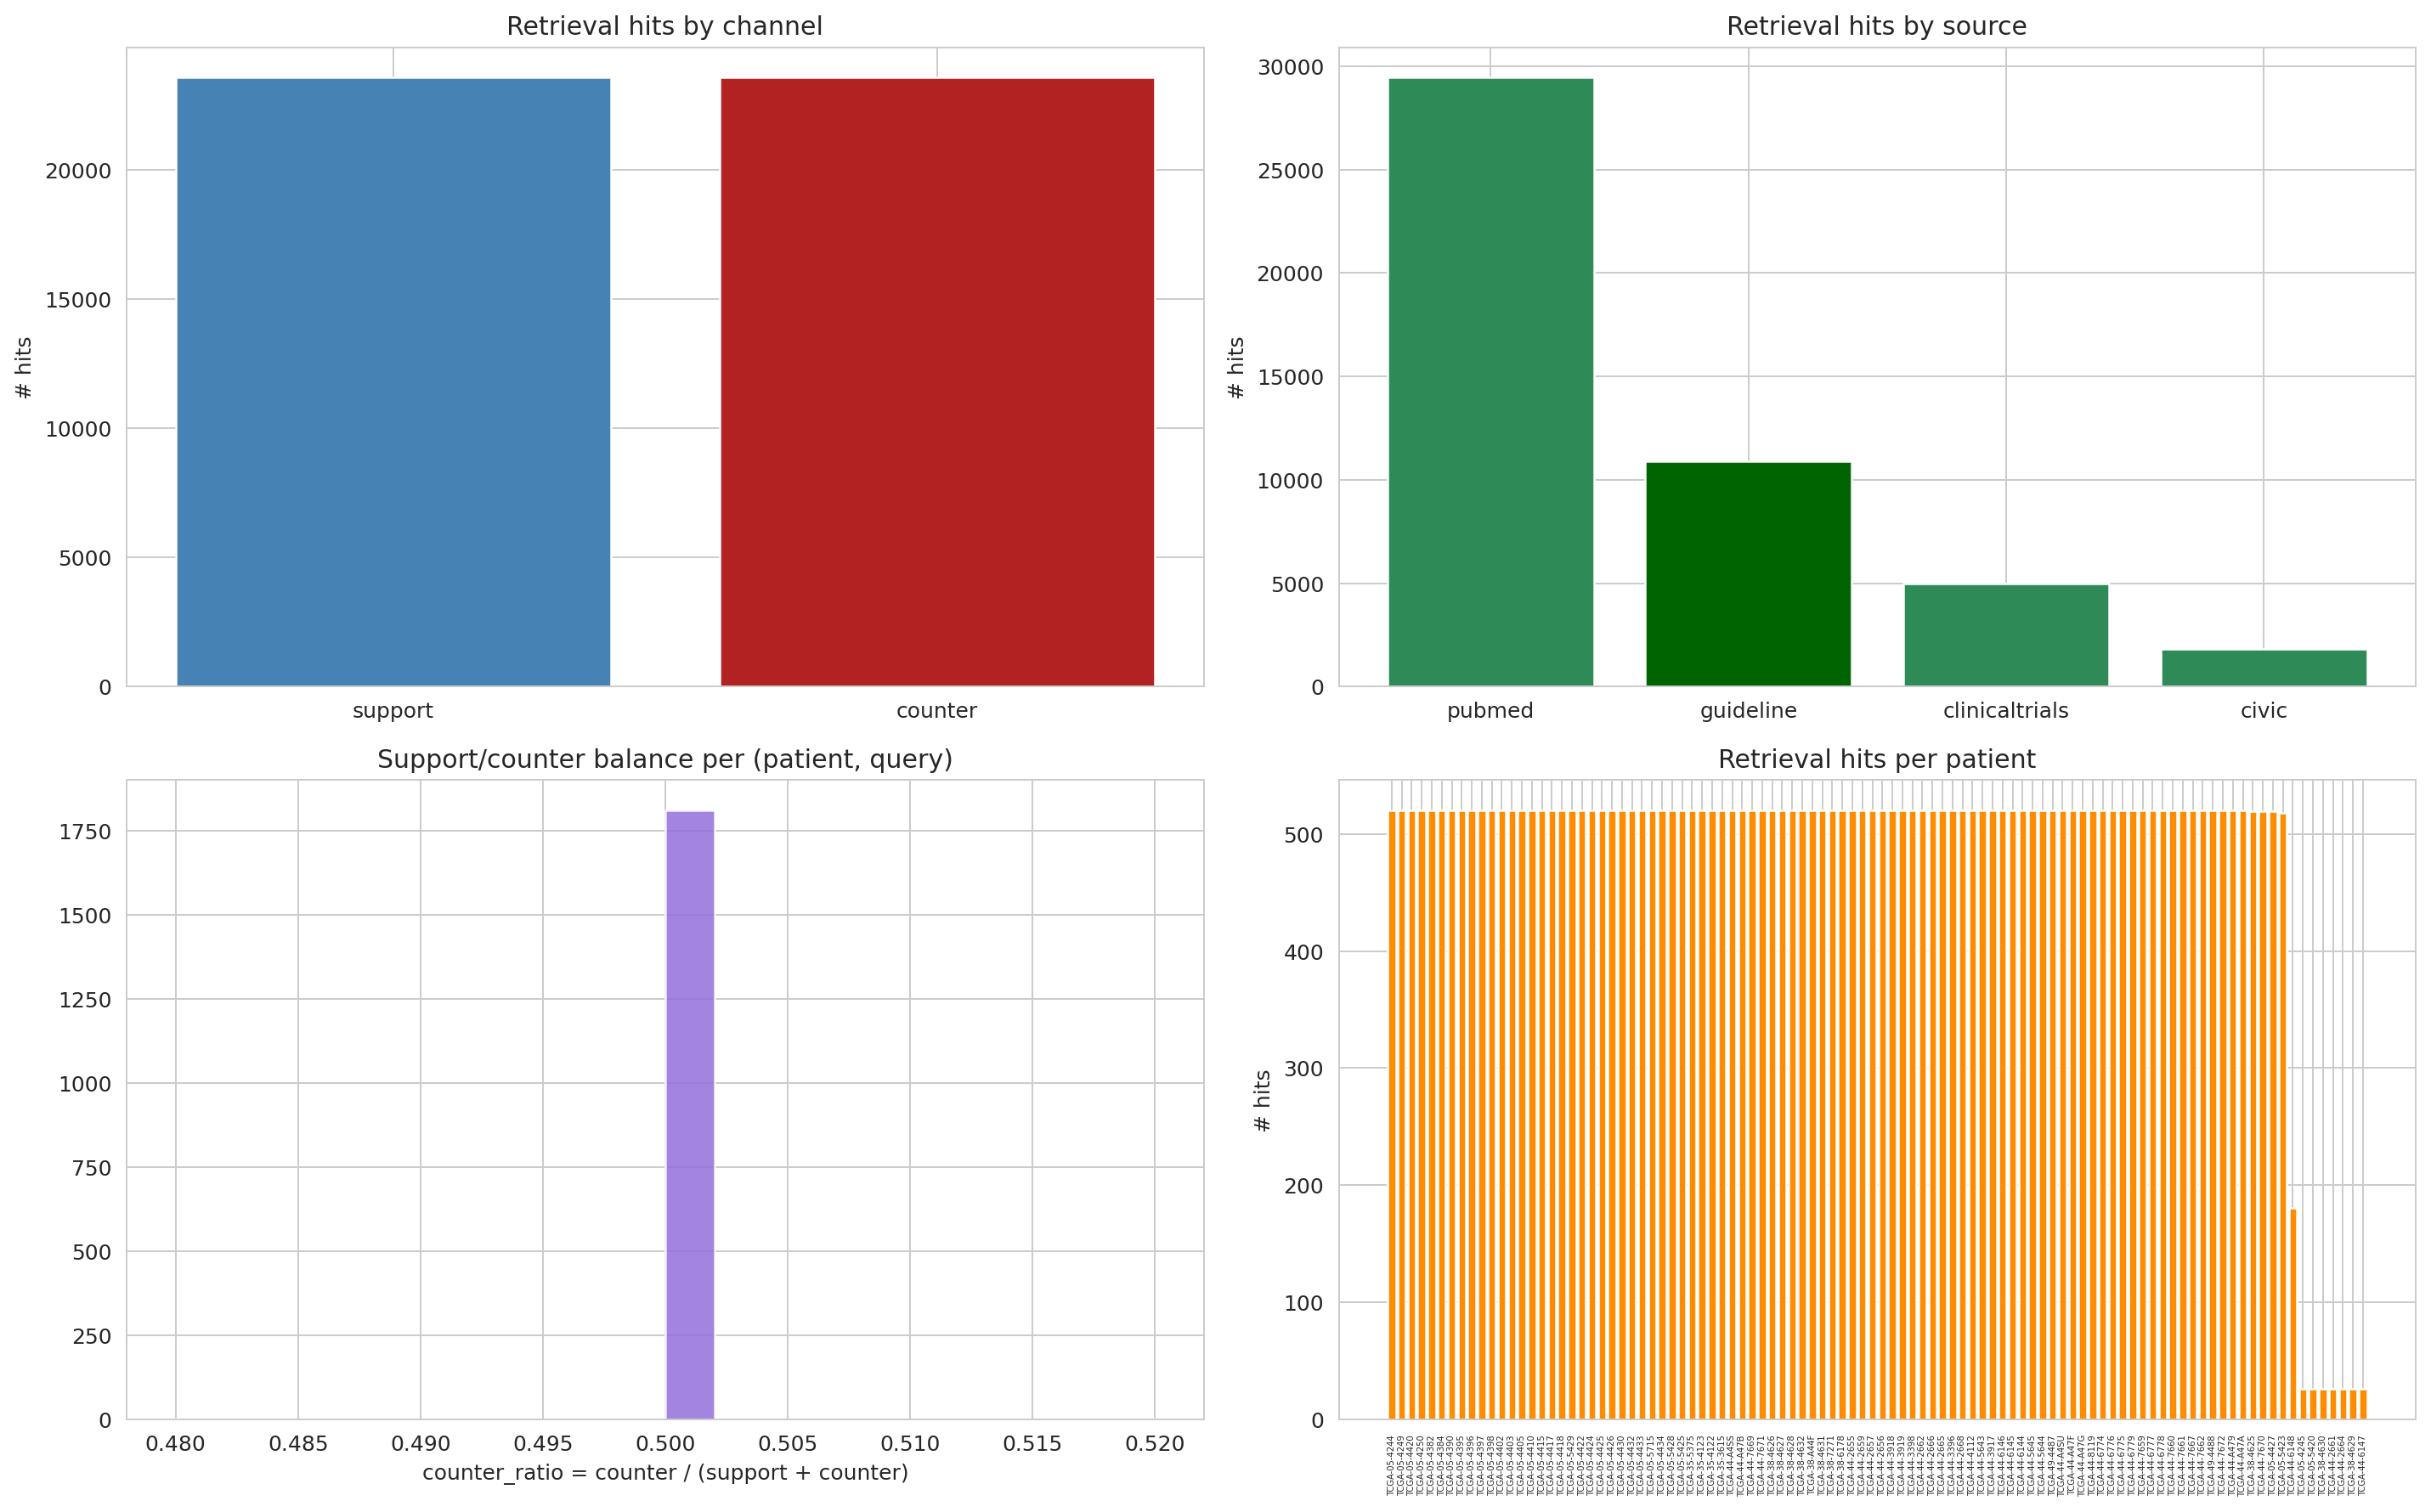

Saved: /kaggle/working/VERIONCO_outputs/05/retrieval_dashboard.png


In [18]:
# ============================================================
# OUTPUTS — Retrieval dashboard
# ============================================================
from IPython.display import Image, display as _display

if len(retrieval_df):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    import seaborn as sns
    sns.set_theme(style='whitegrid', font_scale=1.05)

    fig, axes = plt.subplots(2, 2, figsize=(16, 11))

    # Panel 1: By Channel
    ch = retrieval_df['retrieval_channel'].value_counts()
    colors_ch = ['#2b5c8f', '#b23a22']
    bars_ch = axes[0, 0].bar(ch.index.str.capitalize(), ch.values, color=colors_ch, width=0.55, edgecolor='black', alpha=0.9)
    axes[0, 0].set_title('A. Retrieval Hits by Channel', fontsize=13, fontweight='bold', pad=10)
    axes[0, 0].set_ylabel('Total Retrieval Hits', fontsize=11)
    axes[0, 0].grid(axis='y', linestyle='--', alpha=0.6)
    for bar in bars_ch:
        h = bar.get_height()
        axes[0, 0].text(bar.get_x() + bar.get_width()/2., h + max(ch.values)*0.015,
                        f'{h:,} ({h/len(retrieval_df):.1%})',
                        ha='center', va='bottom', fontsize=10, fontweight='bold')
    axes[0, 0].set_ylim(0, max(ch.values) * 1.15)

    # Panel 2: By Source
    src = retrieval_df['source'].value_counts()
    palette = {'civic': '#1f77b4', 'guideline': '#2ca02c', 'pubmed': '#ff7f0e', 'clinicaltrials': '#9467bd'}
    colors_src = [palette.get(s, '#7f7f7f') for s in src.index]
    src_labels = [s.replace('clinicaltrials', 'CT.gov').capitalize() for s in src.index]
    bars_src = axes[0, 1].bar(src_labels, src.values, color=colors_src, width=0.6, edgecolor='black', alpha=0.9)
    axes[0, 1].set_title('B. Retrieval Hits by Evidence Source', fontsize=13, fontweight='bold', pad=10)
    axes[0, 1].set_ylabel('Total Retrieval Hits', fontsize=11)
    axes[0, 1].grid(axis='y', linestyle='--', alpha=0.6)
    for bar in bars_src:
        h = bar.get_height()
        axes[0, 1].text(bar.get_x() + bar.get_width()/2., h + max(src.values)*0.015,
                        f'{h:,} ({h/len(retrieval_df):.1%})',
                        ha='center', va='bottom', fontsize=10, fontweight='bold')
    axes[0, 1].set_ylim(0, max(src.values) * 1.15)

    # Panel 3: Support/Counter Balance
    if len(balance) and 'counter_ratio' in balance.columns:
        cr = balance['counter_ratio'].dropna()
        axes[1, 0].hist(cr, bins=25, color='#6f42c1', edgecolor='black', alpha=0.85)
        mean_cr, median_cr = cr.mean(), cr.median()
        axes[1, 0].axvline(mean_cr, color='#d9534f', linestyle='--', linewidth=2, label=f'Mean: {mean_cr:.3f}')
        axes[1, 0].axvline(median_cr, color='#f0ad4e', linestyle=':', linewidth=2, label=f'Median: {median_cr:.3f}')
        axes[1, 0].set_xlabel('Counter-Evidence Ratio = counter / (support + counter)', fontsize=11)
        axes[1, 0].set_ylabel('Frequency (Patient-Query pairs)', fontsize=11)
        axes[1, 0].set_title('C. Support / Counter Balance Distribution', fontsize=13, fontweight='bold', pad=10)
        axes[1, 0].legend(loc='upper right', frameon=True)
        axes[1, 0].grid(axis='y', linestyle='--', alpha=0.6)

    # Panel 4: Retrieval Hits per Patient (Clean uncluttered ticks)
    pp = retrieval_df.groupby('patient_id').size().sort_values(ascending=False)
    n_patients = len(pp)
    ranks = np.arange(1, n_patients + 1)
    axes[1, 1].bar(ranks, pp.values, color='#e67e22', width=1.0, edgecolor='none', alpha=0.9, label='Patient Hits')
    axes[1, 1].axhline(pp.mean(), color='#c0392b', linestyle='--', linewidth=2, label=f'Mean: {pp.mean():.1f} hits')
    axes[1, 1].axhline(pp.median(), color='#27ae60', linestyle=':', linewidth=2, label=f'Median: {pp.median():.1f} hits')
    
    tick_positions = [1] + list(range(50, n_patients, 50)) + [n_patients]
    tick_labels = [f'#{pos}' for pos in tick_positions]
    axes[1, 1].set_xticks(tick_positions)
    axes[1, 1].set_xticklabels(tick_labels, fontsize=10)
    axes[1, 1].set_xlim(0, n_patients + 5)
    axes[1, 1].set_xlabel(f'Patient Rank (ordered descending, N={n_patients} patients)', fontsize=11)
    axes[1, 1].set_ylabel('Retrieval Hits Count', fontsize=11)
    axes[1, 1].set_title('D. Retrieval Hits per Patient (Cohort Distribution)', fontsize=13, fontweight='bold', pad=10)
    axes[1, 1].legend(loc='lower left', frameon=True, fontsize=10)
    axes[1, 1].grid(axis='y', linestyle='--', alpha=0.6)

    info_text = (
        f'Cohort Total: {n_patients} patients\n'
        f'Total Hits: {len(retrieval_df):,}\n'
        f'Range: [{pp.min()} - {pp.max()}] hits\n'
        f'Mean ± SD: {pp.mean():.1f} ± {pp.std():.1f}'
    )
    axes[1, 1].text(0.96, 0.95, info_text, transform=axes[1, 1].transAxes,
                    fontsize=9.5, verticalalignment='top', horizontalalignment='right',
                    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#bdc3c7', alpha=0.95))

    plt.tight_layout()
    dash_path = NB_OUTPUT / 'retrieval_dashboard.png'
    plt.savefig(dash_path, dpi=200, bbox_inches='tight')
    _display(Image(filename=str(dash_path)))
    plt.close(fig)
    print('Saved:', dash_path)
else:
    print('No retrieval hits; skipping dashboard.')


In [19]:
import gc
# ============================================================
# OUTPUTS — Final inventory, zip, and completion banner
# ============================================================
import shutil
from pathlib import Path

outputs = []
for p in sorted(NB_OUTPUT.rglob("*")):
    if p.is_file():
        outputs.append({
            "file":       str(p.relative_to(NB_OUTPUT)),
            "size_bytes": p.stat().st_size,
        })

inventory_df = pd.DataFrame(outputs)
display(inventory_df)

total_size_mb = inventory_df["size_bytes"].sum() / (1024 * 1024) if len(inventory_df) else 0
print(f"\nTotal files:       {len(inventory_df)}")
print(f"Total size:        {total_size_mb:.2f} MB")
print(f"Output directory:  {NB_OUTPUT}")

zip_stem = OUTPUT_ROOT / "05_artifacts"
zip_path = Path(str(zip_stem) + ".zip")

if zip_path.exists():
    zip_path.unlink()
    print(f"Removed old zip: {zip_path.name}")

shutil.make_archive(
    base_name=str(zip_stem),
    format="zip",
    root_dir=str(NB_OUTPUT),
)

zip_size_mb = zip_path.stat().st_size / (1024 * 1024)
print(f"\n✓ Zipped artifacts")
print(f"  Path:  {zip_path}")
print(f"  Size:  {zip_size_mb:.2f} MB")

print("\n" + "=" * 50)
print("VERIONCO NOTEBOOK 05 COMPLETE")
print("=" * 50)
print(f"Artifacts:      {NB_OUTPUT}")
print(f"Archive:        {zip_path}")
print(f"Files in zip:   {len(inventory_df)}")
print(f"Zip size:       {zip_size_mb:.2f} MB")
print("=" * 50)

gc.collect()

,file,size_bytes
0,channel_separation.json,456
1,queries.csv,242223
2,retrieval_benchmark.json,1227
3,retrieval_dashboard.png,146712
4,retrieval_hits.csv,16071735
...,...,...
100,retrieval_per_patient/TCGA-44-A4SU.json,173154
101,retrieval_per_patient/TCGA-49-4487.json,172753
102,retrieval_per_patient/TCGA-49-4488.json,173748
103,retrieval_qc_report.json,3072



Total files:       105
Total size:        30.76 MB
Output directory:  /kaggle/working/VERIONCO_outputs/05

✓ Zipped artifacts
  Path:  /kaggle/working/VERIONCO_outputs/05_artifacts.zip
  Size:  1.35 MB

VERIONCO NOTEBOOK 05 COMPLETE
Artifacts:      /kaggle/working/VERIONCO_outputs/05
Archive:        /kaggle/working/VERIONCO_outputs/05_artifacts.zip
Files in zip:   105
Zip size:       1.35 MB


18

## Handoff to Notebook 06 (Hypothesis + Planners)

**Inputs from Notebook 05:**

- `retrieval_hits.csv` — flat table of all support/counter/guideline hits with rank, score, source, source_id, source_url, title.
- `retrieval_per_patient/{patient_id}.json` — per-patient nested retrieval results.
- `support_counter_balance.csv` — per (patient, query) support/counter counts.
- `queries.csv` — the (patient, hypothesis, query) mapping used.
- `retrieval_benchmark.json` — engineering micro-benchmark of channel separation.
- `retrieval_qc_report.json` — QC + documented limitations.

**Guideline integration:**
- Guideline chunks are tagged `source="guideline"` with `source_id` of the form `<pdf_stem>:<chunk_index>`.
- Retrieved via a dedicated BM25 pass (top-3 per query) in addition to the global top-10, because BM25 length-normalization down-ranks long guideline passages.
- Downstream NB06 reads guideline hits via `source == "guideline"` and routes them into `guideline_plan.items`.

**Leakage contract:** every artifact keyed by `patient_id`.

**Critical caveats to carry forward:**

1. Retrieval is against static dumps, not open-domain.
2. Support and counter channels share an index but use separate scoring; downstream notebooks must not collapse them.
3. CIViC evidence here is feature-level (see NB02 `civic_data_limitation.json`).
4. Recall against a clinical gold standard is not measured and must not be claimed.
5. Every recommendation generated in NB06/07 must cite at least one `source_id` from `retrieval_hits.csv` or explicitly be flagged as `no_supporting_retrieval_hit_found`.

In [20]:
import pandas as pd
hits = pd.read_csv("str(NB_OUTPUT / "retrieval_hits.csv")")
print(hits["source"].value_counts().to_string())

guide = hits[hits["source"] == "guideline"]
print(f"\nTotal guideline rows: {len(guide)}")
if len(guide):
    per_pat = guide.groupby("patient_id").size()
    print(f"Patients with >=1 guideline hit: {len(per_pat)} / 98")
    print(f"Mean per patient: {per_pat.mean():.1f}")

source
pubmed            29449
guideline         10884
clinicaltrials     4999
civic              1826

Total guideline rows: 10884
Patients with >=1 guideline hit: 98 / 98
Mean per patient: 111.1


In [ ]:
# ============================================================
# EXPORT & DOWNLOAD ARTIFACT BUNDLE
# ============================================================
import shutil
from pathlib import Path
try:
    from IPython.display import FileLink, display
except ImportError:
    def FileLink(p): return p
    def display(*a): pass

export_dir = OUTPUT_ROOT / 'exports'
export_dir.mkdir(parents=True, exist_ok=True)
zip_name = f'verionco_outputs_{NB_OUTPUT.name}'
zip_path = export_dir / zip_name

# Package NB_OUTPUT into zip
shutil.make_archive(str(zip_path), 'zip', NB_OUTPUT)
final_zip = export_dir / f'{zip_name}.zip'

print('=' * 60)
print(f'VERIONCO NOTEBOOK {NB_OUTPUT.name} COMPLETE')
print(f'Artifact bundle created: {final_zip}')
print(f'Archive size: {final_zip.stat().st_size / (1024*1024):.2f} MB')
print('=' * 60)

# Display download link (clickable in Kaggle/Jupyter)
display(FileLink(str(final_zip)))
